In [28]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency


In [29]:
df = pd.read_csv(r"C:\Users\juanc\OneDrive\Desktop\date analytics 2026\lab-eda-bivariate\amz_uk_price_prediction_dataset.csv")


In [30]:
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [31]:
df.dtypes


uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [32]:
# esto nos da el conteo bruto 

crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [33]:
# proporcion de best sellers por categoria

prop_best = crosstab.div(crosstab.sum(axis=1), axis=0)
prop_best_sorted = prop_best[True].sort_values(ascending=False)
prop_best_sorted.head(10)


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
Name: True, dtype: float64

### ¿Hay categorías donde los productos más vendidos sean más comunes?
Grocery, Smart Home Security & Lighting y Health & Personal Care tienen la mayor proporción relativa de best sellers.

Ojo: no significa que tengan más best sellers en volumen, sino que dentro de su categoría es más probable que un producto sea best seller.

Categorías de consumo recurrente y necesidad básica → más rotación + más probabilidad de best seller.

In [34]:
# Aplicamos un test Chi-cuadrado de independencia para responder esta pregunta
# porq nos pregunta si hay o no! no q tan fuerte... para eso hace falta "Cramér’s V."

from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(crosstab)

chi2, p_value


(np.float64(36540.20270061387), np.float64(0.0))

In [35]:
# aqui si usamos Cramér’s V para medir la fuerza de la asociación entre las variables

import numpy as np

n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))

cramers_v


np.float64(0.1222829439760564)

Aunque existe una relación estadísticamente significativa entre la categoría del producto y su estatus de Best Seller, la fuerza de esta relación es relativamente baja, lo que sugiere que la categoría por sí sola no determina el éxito comercial de un producto.

In [36]:
# quitar outliers de price

# calculo el rango intercuartílico
# elimino precios extremos
# creo un nuevo dataframe limpio para todo Part 2 y 3

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]
df_no_outliers.shape


(2115963, 9)

In [37]:
# top 20 categorias

top_20_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

top_20_categories


Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

C:\Users\juanc\AppData\Local\Temp\ipykernel_15072\306625626.py:4: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


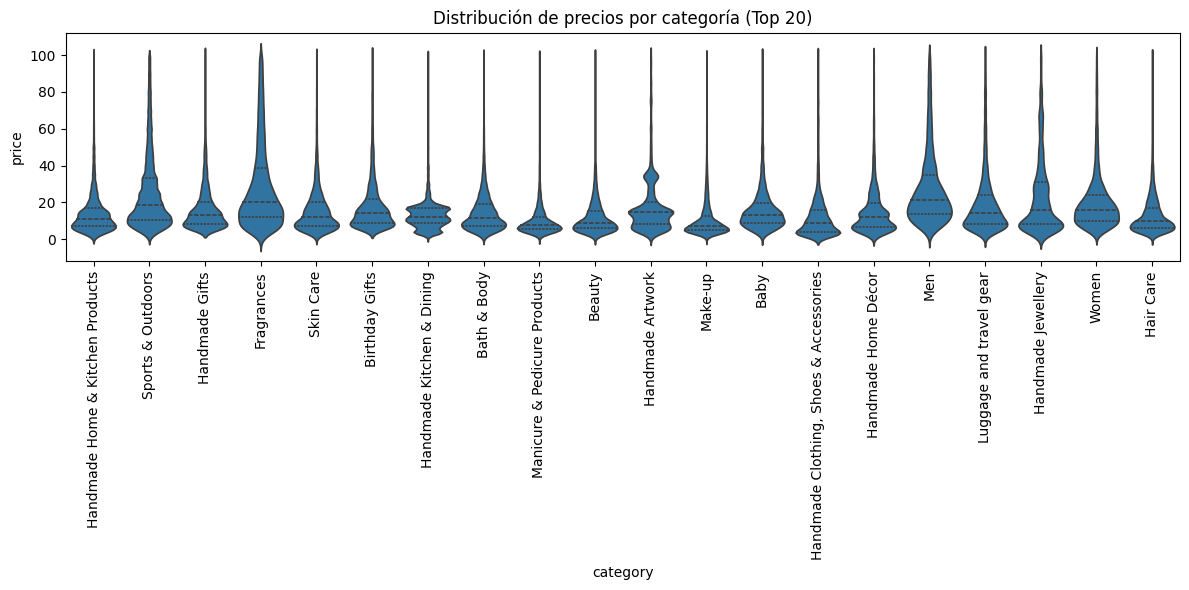

In [38]:
# precio por categoria

plt.figure(figsize=(12, 6))
sns.violinplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top_20_categories)],
    x="category",
    y="price",
    inner="quartile",
    scale="width"
)
plt.xticks(rotation=90)
plt.title("Distribución de precios por categoría (Top 20)")
plt.tight_layout()
plt.show()


### aqui miramos:
- la mediana (línea central)
- la dispersión de precios por categoría
- categorías con precios consistentemente más altos

In [39]:
median_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head(10)


category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

Las categorías relacionadas con la electrónica de consumo y el equipamiento deportivo especializado tienden a tener los precios medios más altos, lo que refleja un mayor valor percibido y una diferenciación funcional.

In [40]:
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

avg_price_top10 = (
    df_no_outliers[df_no_outliers["category"].isin(top_10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_price_top10


category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

Aunque no tiene el precio mediano más alto del dataset,
sí lidera en precio promedio dentro de categorías masivas.
- Indica:
- tickets más altos
- variedad de productos (desde baratos hasta caros)
- buena categoría para escala + margen medio

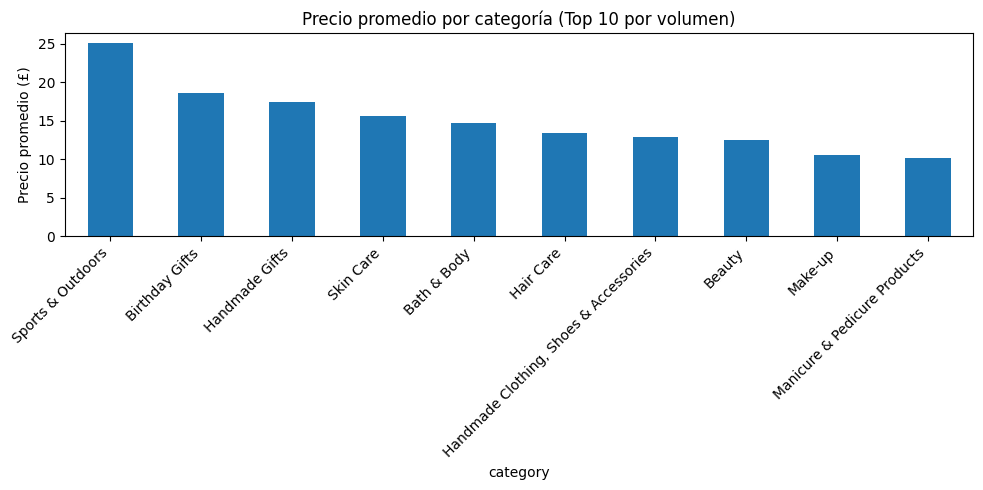

In [41]:
plt.figure(figsize=(10, 5))
avg_price_top10.plot(kind="bar")
plt.ylabel("Precio promedio (£)")
plt.title("Precio promedio por categoría (Top 10 por volumen)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [42]:
top_10_categories_ratings = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

top_10_categories_ratings


Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

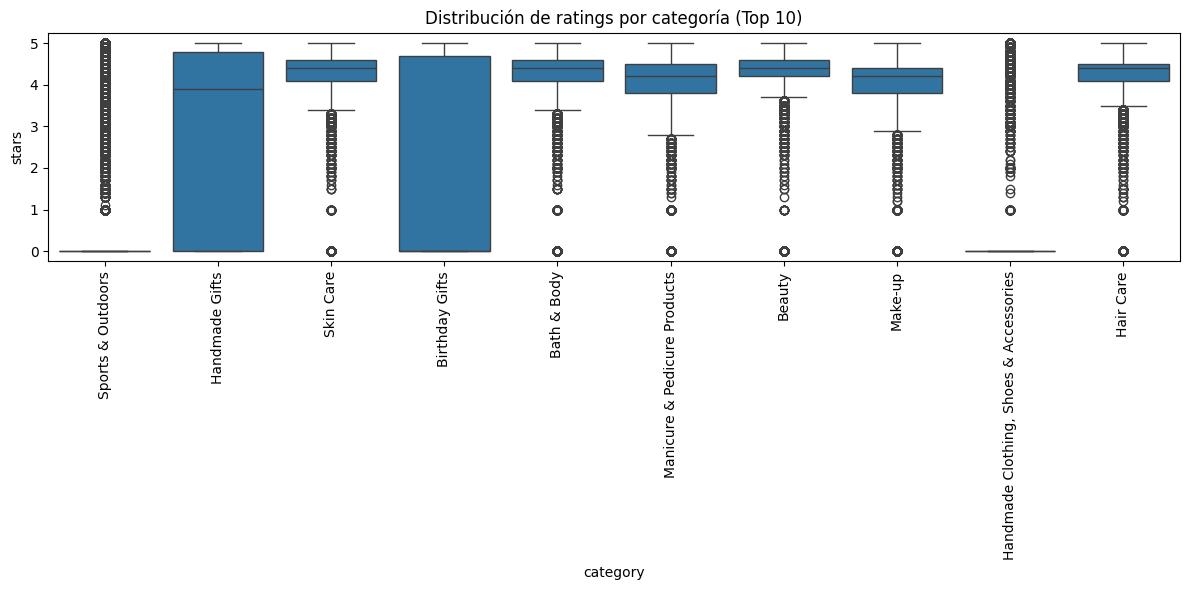

In [43]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top_10_categories_ratings)],
    x="category",
    y="stars"
)
plt.xticks(rotation=90)
plt.title("Distribución de ratings por categoría (Top 10)")
plt.tight_layout()
plt.show()


In [44]:
# coeficiente de correlación entre precio y estrellas

corr_price_stars = df_no_outliers["price"].corr(df_no_outliers["stars"])
corr_price_stars

np.float64(-0.07767299878181444)

El precio del producto muestra una correlación negativa muy débil con las calificaciones de los clientes, lo que indica que los precios más altos no se traducen en una mayor satisfacción percibida.

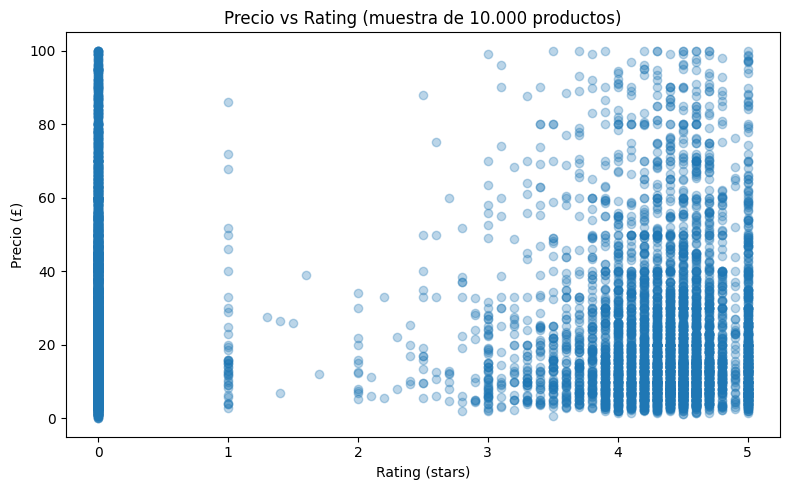

In [45]:
sample_df = df_no_outliers.sample(10000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(
    sample_df["stars"],
    sample_df["price"],
    alpha=0.3
)
plt.xlabel("Rating (stars)")
plt.ylabel("Precio (£)")
plt.title("Precio vs Rating (muestra de 10.000 productos)")
plt.tight_layout()
plt.show()


Este grafico confirma la ausencia de una relación clara entre el precio del producto y las calificaciones de los clientes, observándose rangos de precios similares en todos los niveles de calificación.

In [49]:
# correlación entre variables numéricas

num_cols = ["price", "stars", "reviews", "boughtInLastMonth"]

corr_matrix = df_no_outliers[num_cols].corr()
corr_matrix


,price,stars,reviews,boughtInLastMonth
price,1.000000,-0.077673,-0.008498,-0.059051
stars,-0.077673,1.000000,0.083920,0.113994
reviews,-0.008498,0.083920,1.000000,0.105624
boughtInLastMonth,-0.059051,0.113994,0.105624,1.000000


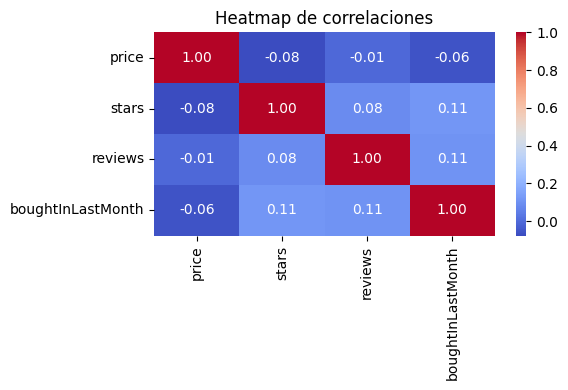

In [50]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Heatmap de correlaciones")
plt.tight_layout()
plt.show()


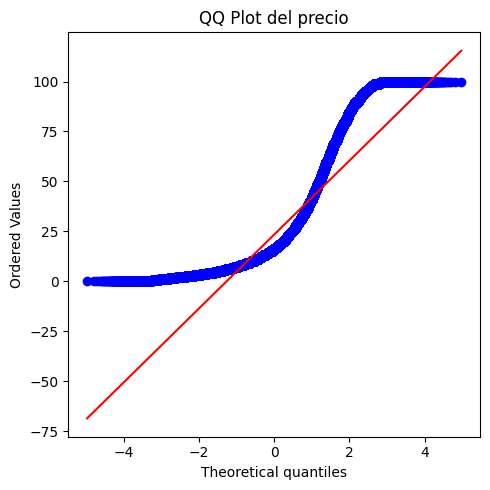

In [51]:
import scipy.stats as stats

plt.figure(figsize=(5, 5))
stats.probplot(df_no_outliers["price"], plot=plt)
plt.title("QQ Plot del precio")
plt.tight_layout()
plt.show()


🎯 Conclusión Final

El éxito de un producto en Amazon UK no depende de un único factor.
La categoría, el precio y los ratings interactúan de forma compleja, donde:

la categoría influye pero no garantiza

el precio no compra satisfacción

el valor percibido manda